<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/heft_smooth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Higgs Effective Field Theory (HEFT) Study: the Smooth $23\times80$ Model
> Created: Oct 31, 2026 Pushpa Bhat (Fermilab), Nicola de Filippis (Bari),<br> Kurtis Johnson,  Harrison B. Prosper, Ryne Starnes (FSU)<br>

## Introduction

The primary model of the di-Higgs $m_{hh}$ spectrum (`docs/smooth/smooth_plan.pdf`, results in `docs/smooth/smooth_results.pdf`). The density is
$$
\frac{d\sigma}{dm}(m;\theta) = \sum_{i=1}^{23} C_i(\theta)\, a_i(m), \qquad a_i(m) = \phi(m)\sum_{j=1}^{J}\beta_{ij} B_j(m),
$$
with the 23 monomials $C_i$ of HEFTNet, cubic B-splines $B_j$ (knots denser near threshold) and the threshold factor $\phi = \sqrt{1 - 4m_h^2/m^2}$. The model's prediction for a bin is the **integral** of the density over the bin, which is linear in the $23J$ numbers $\beta_{ij}$. With a Gaussian likelihood (the exact Poisson variances of the scaled event counts, `dihiggs/counts.py`) and a smoothness prior whose 23 strengths are chosen by the evidence, the posterior is **exactly Gaussian**: no training, no random seeds, no approximation. It takes about a minute on a laptop CPU.

The weights of the likelihood are the model's own Poisson variances, found by iterating (`fit_poisson`): weighting by the observed counts biases a fit low where counts are small.

The model error is added as a discrepancy $\varepsilon(m_{hh})\sum_i|C_i a_i|$, fitted on the training-file rows not used in the fit (`docs/modelerror/new_error_model.pdf`).

In [1]:
import os, sys, time, json, shutil
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from dihiggs import heftnet as NN, counts as CN, laplace as LA
from dihiggs.smooth import SplineBasis, SmoothHEFT
plt.rcParams.update({"text.usetex": shutil.which('latex') is not None, "font.family": "serif", "font.size": 11})

## Switches

| switch | meaning |
| :--- | :--- |
| `J` | number of B-splines per coefficient function (40; 30 and 60 give the same results) |
| `THRESHOLD` | multiply by the phase-space factor $\phi(m)$ (True: much better at threshold) |
| `SECOND_PASS` | refit with the discrepancy in the weights (False; see the results note) |
| `TAG` | the run folder is `runs/SMOOTH_<TAG>` |

In [2]:
J           = 40
THRESHOLD   = True
SECOND_PASS = False
TAG         = f'J{J}' + ('' if THRESHOLD else '_nothr') + ('_pass2' if SECOND_PASS else '')
OUTDIR      = f'runs/SMOOTH_{TAG}'
os.makedirs(OUTDIR, exist_ok=True)
EDGES = 255.0 + 15.0 * np.arange(81)          # the 80 bins of 15 GeV
MHH   = EDGES[:-1] + 7.5                      # bin centres
print('results in', OUTDIR)

results in runs/SMOOTH_J40


## Data

The training file split as in `heft_train.ipynb`: the training and validation rows are fitted (there is no early stopping, so no validation set is needed), together with the restored empty bins; the last 12% (quick-test rows) are kept for the discrepancy. The 1,000 test spectra are used only for validation. The 23 monomials come from HEFTNet itself (`laplace.wilson_coefficients`).

In [3]:
df = pd.read_csv('../data/heft_wide_gauss_traindata_13TeV.csv.gz')
N = len(df); tr = int(0.864 * N); te = int(0.120 * N); va = N - tr - te
counted, quanta = CN.recover_counts(df)
full  = CN.add_empty_bins(counted)
fit   = pd.concat([counted.iloc[:tr + va], full[full['count'] == 0]], ignore_index=True)
quick = counted.iloc[tr + va:]

monomials = NN.HEFTNet().double()           # only its C_i(theta) are used
def C_of(frame):
    return LA.wilson_coefficients(monomials, torch.tensor(frame[NN.FEATURES].to_numpy(np.float64))).numpy()
def bin_of(frame):
    # the input mhh is (m - 255 GeV)/1500 GeV at the bin centre
    return np.rint(frame['mhh'].to_numpy() * 100 - 0.5).astype(int)

C_fit, b_fit, t_fit, q_fit = C_of(fit), bin_of(fit), fit.sigma.to_numpy(), fit.quantum.to_numpy()
C_q, b_q, t_q, q_q = C_of(quick), bin_of(quick), quick.sigma.to_numpy(), quick.quantum.to_numpy()

spectra = pd.read_csv('../data/heft_wide_gauss_testdata_13TeV.csv')
bins = [c for c in spectra.columns if c.isdigit()]
T = spectra[bins].to_numpy(np.float64); nS = len(T)
_, q_t, _ = CN.recover_counts_wide(T)
theta = spectra[['klambda', 'CT', 'CTT', 'CGGH', 'CGGHH']].to_numpy(np.float32).astype(np.float64)
x_bins = (np.arange(80) + 0.5) / 100
C_t = LA.wilson_coefficients(monomials, torch.tensor(np.column_stack([np.tile(x_bins, nS), np.repeat(theta, 80, axis=0)]))).numpy()
print(f'fit rows {len(fit)}, quick-test rows {len(quick)}, test spectra {nS}')

fit rows 281044, quick-test rows 38076, test spectra 1000


## The fit

`fit_poisson` alternates between a weighted fit and new weights from the model's Poisson variances; the 23 smoothness strengths are chosen by the evidence (MacKay's updates) in the first pass and again at the end.

In [4]:
basis = SplineBasis(J, threshold=THRESHOLD)
I = basis.integrals(EDGES)                     # [80, J]: integrals of phi*B_j over each bin
t0 = time.time()
model = SmoothHEFT(basis).fit_poisson(C_fit, I[b_fit], t_fit, q_fit, verbose=True)

def S_of(model, C, b):
    # sum_i |C_i a_ik|, the size of the individual terms in bin k
    A = model.coefficient_integrals(I)
    return np.abs(C * A[b]).sum(1)

def fit_eps(model):
    # epsilon(m)^2 bin by bin on the quick-test rows, from <z^2> = 1; then
    # ln(epsilon) smoothed by a quadratic in m
    f, v = model.predict(C_q, I[b_q]); noise = q_q * np.maximum(f, q_q); S = S_of(model, C_q, b_q)
    e2 = np.zeros(80)
    for k in range(80):
        s = b_q == k; r2 = (t_q - f)[s]**2
        g = lambda c: np.mean(r2 / (noise[s] + v[s] + c * S[s]**2)) - 1
        e2[k] = 0.0 if g(0) <= 0 else brentq(g, 0, 1.0)
    u = (MHH - 855) / 600; ok = e2 > 0; nb = np.bincount(b_q, minlength=80)
    p = np.polyfit(u[ok], 0.5 * np.log(e2[ok]), 2, w=np.sqrt(nb[ok]))
    return np.exp(np.polyval(p, u)), np.sqrt(e2), p

eps, eps_bin, eps_poly = fit_eps(model)
if SECOND_PASS:
    extra = (eps[b_fit] * S_of(model, C_fit, b_fit))**2
    model = SmoothHEFT(basis).fit_poisson(C_fit, I[b_fit], t_fit, q_fit, extra_var=extra, verbose=True)
    eps, eps_bin, eps_poly = fit_eps(model)
print(f'{time.time() - t0:.0f} s; ln Z = {model.log_evidence():.1f}; well-determined combinations: {model.gamma().sum():.0f} of {model.P}')
print('epsilon at 262, 600, 1447 GeV (%):', np.round(100 * eps[[0, 23, 79]], 3))

  IRLS pass 1: 99% of the variances changed by less than 3.6e-01


  IRLS pass 2: 99% of the variances changed by less than 1.6e-01


  IRLS pass 3: 99% of the variances changed by less than 8.3e-02


  IRLS pass 4: 99% of the variances changed by less than 5.0e-02


  IRLS pass 5: 99% of the variances changed by less than 3.2e-02


  IRLS pass 6: 99% of the variances changed by less than 2.0e-02


... (3 outputs left out)

  IRLS pass 10: 99% of the variances changed by less than 2.4e-03


  IRLS pass 11: 99% of the variances changed by less than 1.3e-03


  IRLS pass 12: 99% of the variances changed by less than 7.5e-04


73 s; ln Z = -165302.1; well-determined combinations: 602 of 920
epsilon at 262, 600, 1447 GeV (%): [0.077 0.279 3.687]


## Validation on the 1,000 test spectra

Pulls $z = (t - f)/\sqrt{q f + s^2 + s_\text{disc}^2}$, with the Poisson noise at the prediction, the exact fit uncertainty $s^2$ and the discrepancy; overall, by region and by degree of cancellation.

In [5]:
f, v = model.predict(C_t, np.tile(I, (nS, 1))); f, v = f.reshape(nS, 80), v.reshape(nS, 80)
S_t = S_of(model, C_t, np.tile(np.arange(80), nS)).reshape(nS, 80)
noise = q_t[:, None] * np.maximum(f, q_t[:, None])
use = (T > 0) | (f > 0)
canc = T.sum(1) / S_t.sum(1); q5 = np.quantile(canc, [0, .2, .4, .6, .8, 1])
n = T / q_t[:, None]; mu = f / q_t[:, None]; pos = mu > 0
deviance = np.where(pos, 2 * (mu - n + np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / np.where(pos, mu, 1)), 0)), np.nan)
print(f'Poisson deviance per bin: 255-555 GeV {np.nanmean(deviance[:, :20]):.3f}, above {np.nanmean(deviance[:, 20:]):.3f}; median per spectrum {np.median(np.nanmean(deviance, 1)):.3f}')
for label, extra in [('noise + fit', 0.0), ('noise + fit + discrepancy', (eps[None] * S_t)**2)]:
    z = np.where(use, (T - f) / np.sqrt(noise + v + extra), np.nan)
    quint = [np.nanmean(z[(canc >= a) & (canc <= b)]**2) for a, b in zip(q5[:-1], q5[1:])]
    print(f'{label:28s} pull s.d. {np.nanstd(z):.3f} ({np.nanstd(z[:, :20]):.3f}, {np.nanstd(z[:, 20:]):.3f}); '
          f'|z|<2 {np.nanmean(np.abs(z) < 2):.3f}; <z^2> by cancellation fifth {np.round(quint, 2)}')

Poisson deviance per bin: 255-555 GeV 1.566, above 1.100; median per spectrum 1.078
noise + fit                  pull s.d. 1.090 (1.218, 1.043); |z|<2 0.939; <z^2> by cancellation fifth [1.7  1.1  1.07 1.06 1.01]
noise + fit + discrepancy    pull s.d. 1.004 (1.011, 1.001); |z|<2 0.954; <z^2> by cancellation fifth [0.97 0.98 1.04 1.04 1.  ]


## The coefficient functions, and saving the model

The 23 $a_i(m)$ as continuous curves with their exact $\pm1\sigma$ bands. The model is saved as `smooth_model.npz`: the knots, the threshold flag, $\hat\beta$, the posterior precision $H$, the smoothness strengths and the discrepancy; with `dihiggs.smooth` that is all one needs to predict any binning.

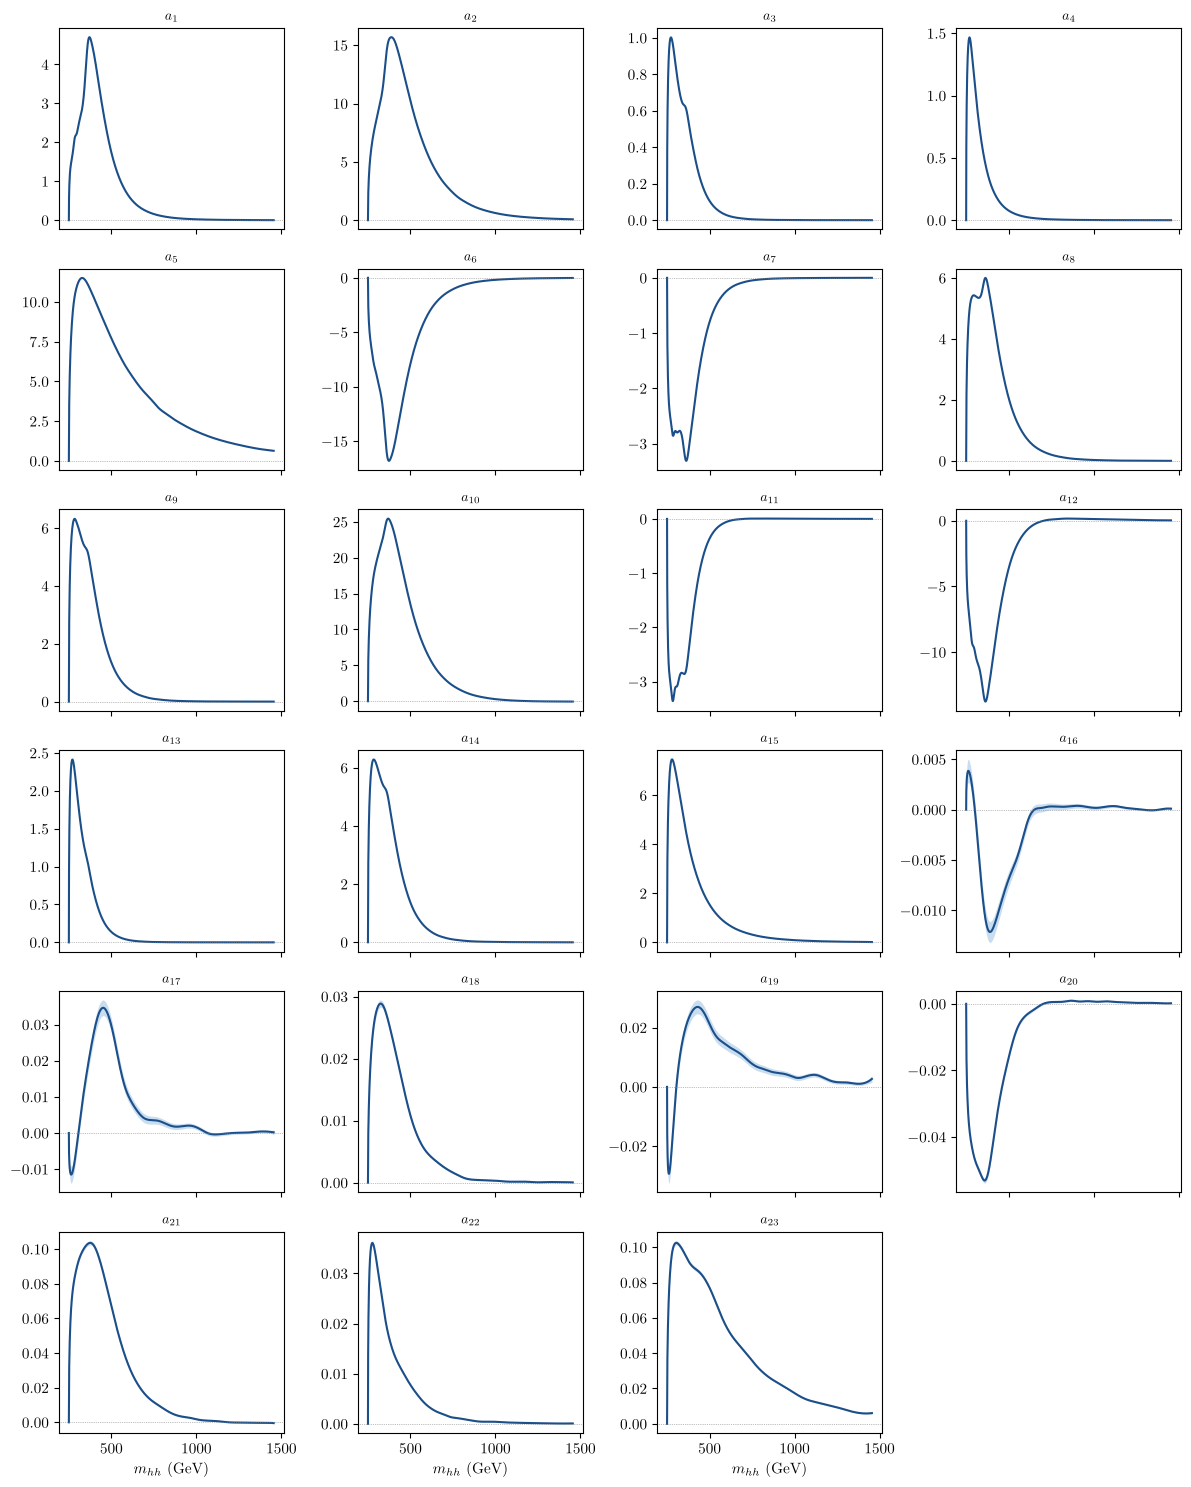

In [6]:
mg = np.linspace(250, 1455, 1206)
a, sd = model.coefficients(mg)
fig, axes = plt.subplots(6, 4, figsize=(12, 15), sharex=True)
for i, ax in enumerate(axes.flat[:23]):
    y, s = 15e3 * a[:, i], 15e3 * sd[:, i]           # fb per 15 GeV
    ax.fill_between(mg, y - s, y + s, color='#C9DDF0', lw=0); ax.plot(mg, y, color='#1B4F8A')
    ax.axhline(0, color='gray', lw=0.5, ls=':'); ax.set_title(f'$a_{{{i+1}}}$', fontsize=10)
axes.flat[23].axis('off')
for ax in axes[-1]: ax.set_xlabel(r'$m_{hh}$ (GeV)')
fig.tight_layout(); plt.savefig(f'{OUTDIR}/smooth_coefficients.png'); plt.show()

np.savez(f'{OUTDIR}/smooth_model.npz', breaks=basis.breaks, threshold=THRESHOLD, m_lo=basis.m_lo, m_hi=basis.m_hi,
         beta=model.beta, H=model.H, lam=model.lam, eps_poly=eps_poly, eps=eps)
json.dump({'J': J, 'threshold': THRESHOLD, 'second_pass': SECOND_PASS, 'lnZ': model.log_evidence(),
           'gamma': float(model.gamma().sum())}, open(f'{OUTDIR}/summary.json', 'w'), indent=1)